# Chapitre 4 - Méthodes linéaires de classification
## Cours 2 : LDA de rang réduit et variables canoniques de Fisher

Ce notebook traite la section 4.3.3 du livre. La LDA ne fournit pas seulement une règle
de classification : elle fournit aussi des **projections de faible dimension** des
données, les plus informatives pour distinguer les classes. Nous reproduisons sur les
données de voyelles les figures 4.4, 4.8, 4.10 et 4.11, et illustrons la figure 4.9.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

In [2]:
Xtr, ytr = datasets.load_vowel("train")
Xte, yte = datasets.load_vowel("test")
K, p = len(np.unique(ytr)), Xtr.shape[1]
print("K =", K, " p =", p, " N_train =", len(ytr), " N_test =", len(yte))

K = 11  p = 10  N_train = 528  N_test = 462


Pour représenter 11 classes, nous utilisons une palette de 11 couleurs : les 8 couleurs
catégorielles du projet, complétées par trois teintes neutres.

In [3]:
VOW = COLORS + ["#52514e", "#8c6d31", "#17becf"]
classes = np.arange(1, 12)

## 1. Pourquoi une réduction de dimension est possible

Rappelons (cours 1) que, après **blanchiment** $x^* = \mathbf{W}^{-1/2}x$ par la covariance
intra-classe $\mathbf{W} = \hat\Sigma$, la LDA classe au **centroïde le plus proche**
(corrigé par $\log\pi_k$).

Les $K$ centroïdes $\mu_1^*, \dots, \mu_K^*$ engendrent un sous-espace affine
$H_{K-1}$ de dimension au plus $K-1$. Décomposons $x^* - \mu_k^*$ en sa composante dans
la direction de $H_{K-1}$ et sa composante orthogonale. Par le théorème de Pythagore,
$$\|x^*-\mu_k^*\|^2 = \|P(x^*) - \mu_k^*\|^2 + \|x^* - P(x^*)\|^2,$$
où $P$ est la projection orthogonale sur $H_{K-1}$. Le second terme **ne dépend pas de
$k$** : il ne joue aucun rôle dans la comparaison.

> **À retenir.** La LDA peut s'effectuer intégralement dans $H_{K-1}$, de dimension
> $K - 1$. Avec $K = 3$ classes, on peut donc voir *toute* l'information utile de la LDA
> dans un plan, quelle que soit la dimension $p$ des données.

Quand $K - 1$ est encore grand (ici $K - 1 = 10 = p$), on cherche un sous-espace
$H_L \subset H_{K-1}$ de dimension $L$ optimal : celui où les centroïdes projetés sont
**le plus dispersés possible**, au sens de la variance.

## 2. Construction des variables canoniques

La procédure du livre comporte trois étapes :

1. calculer la matrice $\mathbf{M}$ ($K\times p$) des centroïdes de classe et la covariance
   intra-classe $\mathbf{W}$ ($p \times p$) ;
2. calculer $\mathbf{M}^* = \mathbf{M}\mathbf{W}^{-1/2}$ (centroïdes blanchis) ;
3. calculer $\mathbf{B}^*$, matrice de covariance (pondérée par les $\pi_k$) des lignes de
   $\mathbf{M}^*$, et sa décomposition spectrale
   $\mathbf{B}^* = \mathbf{V}^*\mathbf{D}_B\mathbf{V}^{*T}$ (valeurs propres décroissantes).

La $\ell$-ième **variable canonique** (ou coordonnée discriminante) est
$Z_\ell = v_\ell^T X$ avec $v_\ell = \mathbf{W}^{-1/2}v_\ell^*$.

Rappel : pour une matrice symétrique définie positive $\mathbf{W} = \mathbf{U}\mathbf{D}\mathbf{U}^T$,
on définit $\mathbf{W}^{-1/2} = \mathbf{U}\mathbf{D}^{-1/2}\mathbf{U}^T$ ; c'est l'unique
matrice symétrique définie positive telle que $(\mathbf{W}^{-1/2})^2 = \mathbf{W}^{-1}$.

Appliquons ces trois étapes « à la main » sur les voyelles.

In [4]:
lda = c4.lda_fit(Xtr, ytr)
M, W, pi = lda["means"], lda["cov"], lda["priors"]
dW, UW = np.linalg.eigh(W)
W_m12 = UW @ np.diag(dW ** -0.5) @ UW.T            # W^{-1/2}
Mstar = M @ W_m12
Mstar_c = Mstar - pi @ Mstar                        # centrage pondéré
Bstar = (Mstar_c * pi[:, None]).T @ Mstar_c
dB, Vstar = np.linalg.eigh(Bstar)
order = np.argsort(dB)[::-1]
dB, Vstar = dB[order], Vstar[:, order]
V_main = W_m12 @ Vstar                              # directions v_l
np.round(dB, 4)

array([3.9676e+00, 2.4853e+00, 3.1460e-01, 1.3520e-01, 7.5300e-02,
       5.8600e-02, 1.8200e-02, 7.5000e-03, 1.0000e-03, 6.0000e-04])

### Le point de vue de Fisher

Fisher aborde la question autrement : trouver la combinaison linéaire $Z = a^TX$ dont la
variance **entre classes** est la plus grande possible relativement à sa variance **à
l'intérieur des classes**. Si $\mathbf{B}$ désigne la covariance des centroïdes (non
blanchis), la variance inter-classes de $Z$ vaut $a^T\mathbf{B}a$ et sa variance
intra-classe $a^T\mathbf{W}a$. Fisher maximise le **quotient de Rayleigh** (éq. (4.15)) :
$$\max_a \frac{a^T\mathbf{B}a}{a^T\mathbf{W}a}
\quad\Longleftrightarrow\quad \max_a a^T\mathbf{B}a \ \text{ sous } \ a^T\mathbf{W}a = 1.$$

Ce problème aux valeurs propres **généralisé** se ramène à un problème standard en posant
$b = \mathbf{W}^{1/2}a$ (exercice 4.1) : on maximise $b^T\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}b$
sous $\|b\| = 1$, et $\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2} = \mathbf{B}^*$. La
solution est donc $a_1 = v_1$, et le maximum vaut la plus grande valeur propre de
$\mathbf{B}^*$. Les directions suivantes $a_2, a_3, \dots$ maximisent le même quotient
sous la contrainte d'être $\mathbf{W}$-orthogonales aux précédentes
($a_\ell^T\mathbf{W}a_m = 0$) : ce sont $v_2, v_3, \dots$

Vérifions numériquement : (i) la fonction `reduced_rank_lda_fit` du module (qui résout
directement $\mathbf{B}v = \lambda\mathbf{W}v$ avec `scipy.linalg.eigh`) donne les mêmes
directions au signe près ; (ii) le quotient de Rayleigh de $v_\ell$ vaut $\lambda_\ell$.

In [5]:
rr = c4.reduced_rank_lda_fit(Xtr, ytr)
V = rr["scalings"]
B = ((M - rr["center"]) * pi[:, None]).T @ (M - rr["center"])
cos = np.abs(np.sum(V * V_main, axis=0)) / (np.linalg.norm(V, axis=0) * np.linalg.norm(V_main, axis=0))
rayleigh = np.array([(v @ B @ v) / (v @ W @ v) for v in V.T])
print("|cos(angle)| entre les deux constructions :", np.round(cos, 6))
print("Quotients de Rayleigh :", np.round(rayleigh, 4))
print("V^T W V = I :", np.allclose(V.T @ W @ V, np.eye(p)))

|cos(angle)| entre les deux constructions : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Quotients de Rayleigh : [3.9676e+00 2.4853e+00 3.1460e-01 1.3520e-01 7.5300e-02 5.8600e-02
 1.8200e-02 7.5000e-03 1.0000e-03 6.0000e-04]
V^T W V = I : True


Les variances inter-classes décroissent vite : les deux premières variables canoniques
portent l'essentiel de la dispersion des centroïdes.

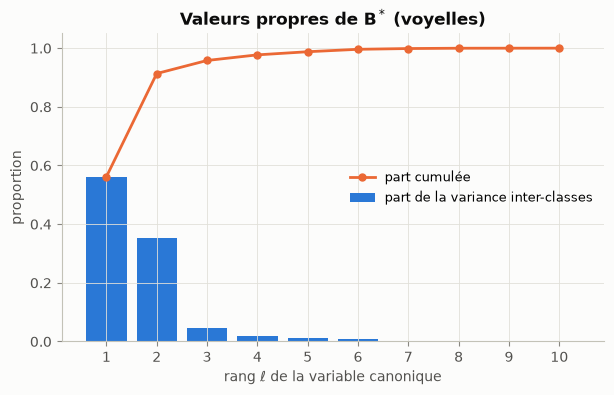

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(1, p + 1), rr["eigvals"] / rr["eigvals"].sum(), color=BLUE, label="part de la variance inter-classes")
ax.plot(np.arange(1, p + 1), np.cumsum(rr["eigvals"]) / rr["eigvals"].sum(), "o-", color=ORANGE, label="part cumulée")
ax.set_title("Valeurs propres de $\\mathbf{B}^*$ (voyelles)")
ax.set_xlabel("rang $\\ell$ de la variable canonique")
ax.set_ylabel("proportion")
ax.set_xticks(np.arange(1, p + 1))
ax.legend(loc="center right")
plt.show()

## 3. Visualisation des voyelles (figures 4.4 et 4.8)

On projette les données d'apprentissage sur les deux premières variables canoniques ; les
gros cercles sont les centroïdes projetés.

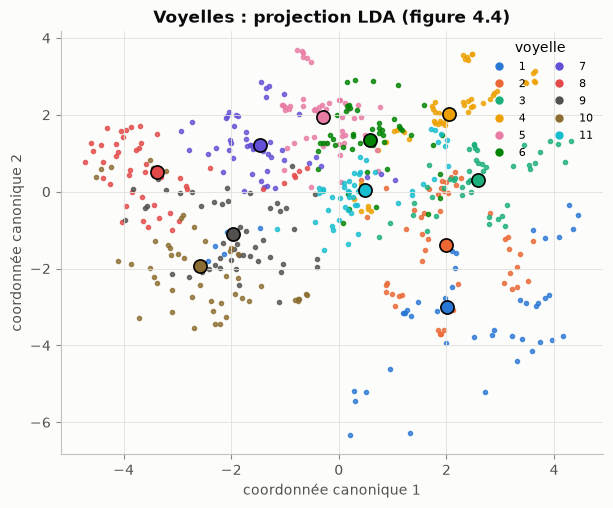

In [7]:
Ztr = c4.reduced_rank_lda_transform(rr, Xtr)
Zc = c4.reduced_rank_lda_transform(rr, M)

def plot_canonical(ax, i, j, title=None):
    for k in range(K):
        ax.scatter(Ztr[ytr == k + 1, i], Ztr[ytr == k + 1, j], s=9, color=VOW[k], alpha=0.8)
        ax.scatter(Zc[k, i], Zc[k, j], s=90, color=VOW[k], edgecolor="k", lw=1.2, zorder=3)
    ax.set_xlabel("coordonnée canonique %d" % (i + 1))
    ax.set_ylabel("coordonnée canonique %d" % (j + 1))
    if title:
        ax.set_title(title)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_canonical(ax, 0, 1, "Voyelles : projection LDA (figure 4.4)")
handles = [plt.Line2D([], [], marker="o", ls="", color=VOW[k], label=str(k + 1)) for k in range(K)]
ax.legend(handles=handles, title="voyelle", ncol=2, loc="upper right", fontsize=8)
plt.show()

Le recouvrement des classes reste important, même dans la « meilleure » vue. Regardons
d'autres paires de coordonnées canoniques (figure 4.8).

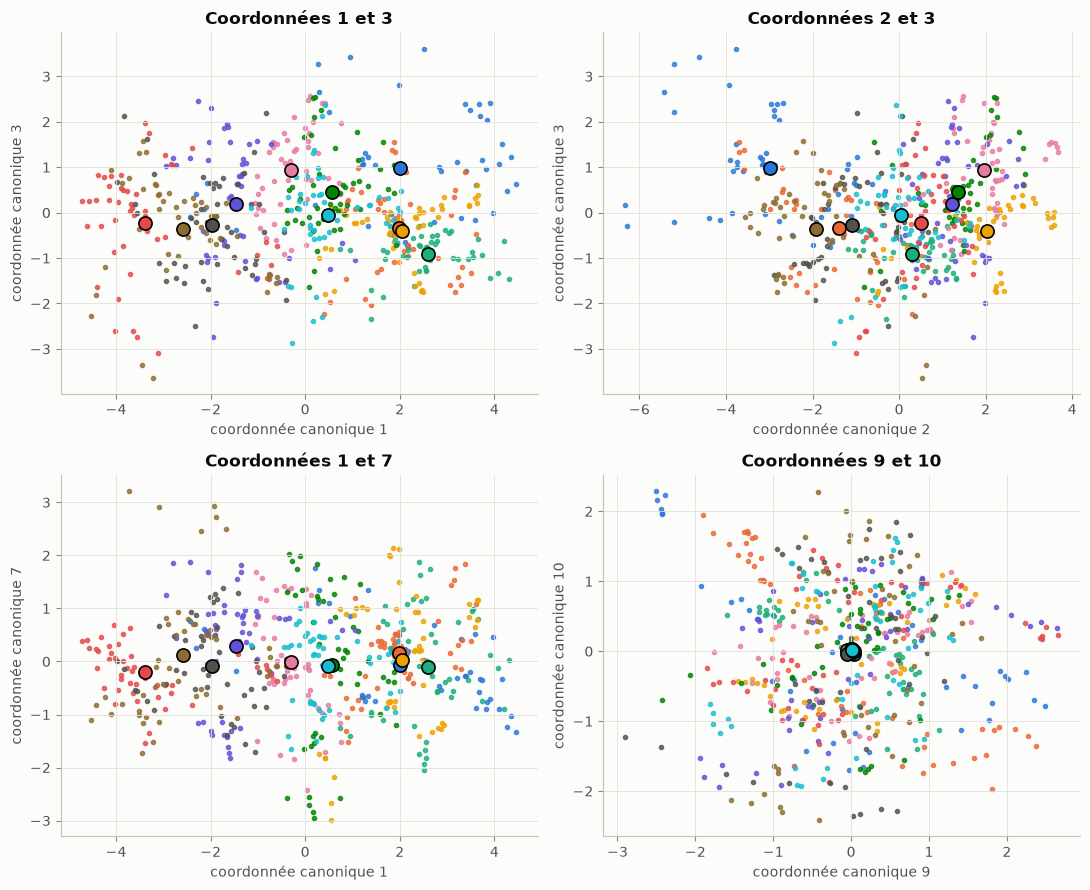

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (i, j) in zip(axes.ravel(), [(0, 2), (1, 2), (0, 6), (8, 9)]):
    plot_canonical(ax, i, j, "Coordonnées %d et %d" % (i + 1, j + 1))
fig.tight_layout()
plt.show()

Plus le rang des coordonnées augmente, plus les centroïdes sont **resserrés** : sur les
coordonnées 9 et 10, ils sont presque confondus et les classes indiscernables. C'est la
traduction graphique de la décroissance des valeurs propres $\lambda_\ell$.

## 4. Pourquoi ne pas simplement projeter sur la droite des centroïdes ? (figure 4.9)

Avec deux classes, la direction qui disperse le plus les centroïdes est celle de
$\mu_2 - \mu_1$. Mais si la covariance intra-classe est allongée en biais, les données
projetées sur cette droite se **recouvrent** beaucoup. La direction discriminante
$\mathbf{W}^{-1}(\mu_2-\mu_1)$ tient compte de la covariance et minimise ce recouvrement
(pour des données gaussiennes).

In [9]:
rng = np.random.RandomState(0)
S49 = np.array([[1.0, 0.85], [0.85, 1.0]])
mu49 = np.array([[0.0, 0.0], [1.2, -0.3]]) * 1.6
L49 = np.linalg.cholesky(S49)
X49 = np.vstack([rng.randn(200, 2) @ L49.T + m for m in mu49])
g49 = np.repeat([0, 1], 200)
lda49 = c4.lda_fit(X49, g49)
dirs = {"droite des centroïdes": lda49["means"][1] - lda49["means"][0],
        "direction discriminante": np.linalg.solve(lda49["cov"], lda49["means"][1] - lda49["means"][0])}

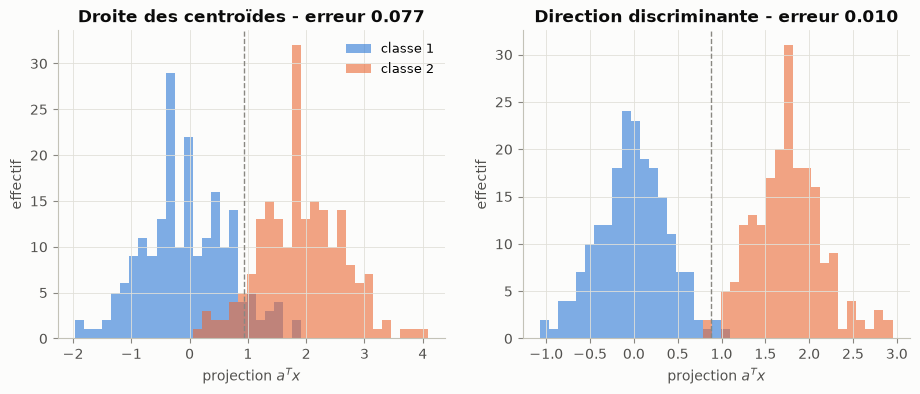

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nom, a) in zip(axes, dirs.items()):
    a = a / np.linalg.norm(a)
    z = X49 @ a
    zc = lda49["means"] @ a
    cut = zc.mean()                                   # coupure au milieu (classes équilibrées)
    err = np.mean((z > cut).astype(int) != g49) if zc[1] > zc[0] else np.mean((z < cut).astype(int) != g49)
    bins = np.linspace(z.min(), z.max(), 40)
    for k, col in enumerate([BLUE, ORANGE]):
        ax.hist(z[g49 == k], bins=bins, color=col, alpha=0.6, label="classe %d" % (k + 1))
    ax.axvline(cut, color=GRAY, ls="--", lw=1)
    ax.set_title("%s - erreur %.3f" % (nom.capitalize(), err))
    ax.set_xlabel("projection $a^T x$")
    ax.set_ylabel("effectif")
axes[0].legend()
plt.show()

Le recouvrement est bien plus faible dans la direction discriminante, et l'erreur de
classification nettement plus basse.

> **Intuition.** Il faut « mesurer » la séparation des centroïdes en **unités de l'écart
> type intra-classe dans la direction considérée** : c'est exactement ce que fait le
> quotient $a^T\mathbf{B}a / a^T\mathbf{W}a$.

## 5. Classification dans un sous-espace réduit (figures 4.10 et 4.11)

On peut aussi **classer** dans le sous-espace des $L$ premières variables canoniques :
on calcule $z = (v_1^Tx, \dots, v_L^Tx)$ et on choisit
$$\hat G_L(x) = \operatorname*{arg\,min}_k \Big(\tfrac12 \|z - \bar z_k\|^2 - \log\pi_k\Big),$$
où $\bar z_k$ est le centroïde projeté de la classe $k$. Pour $L = \min(p, K-1)$, on
retrouve exactement la LDA (section 1). L'exercice 4.8 montre que cette règle est la règle
de Bayes d'un modèle gaussien dont les centroïdes sont **contraints** à vivre dans un
sous-espace de dimension $L$, ajusté par maximum de vraisemblance.

> **Remarque (le terme $\log\pi_k$).** Il vient du modèle gaussien : si les classes ont
> des probabilités a priori différentes, il est avantageux de déplacer le point de coupure
> vers la classe la plus petite. Ici les 11 classes ont le même effectif (48), donc ce terme
> ne change rien.

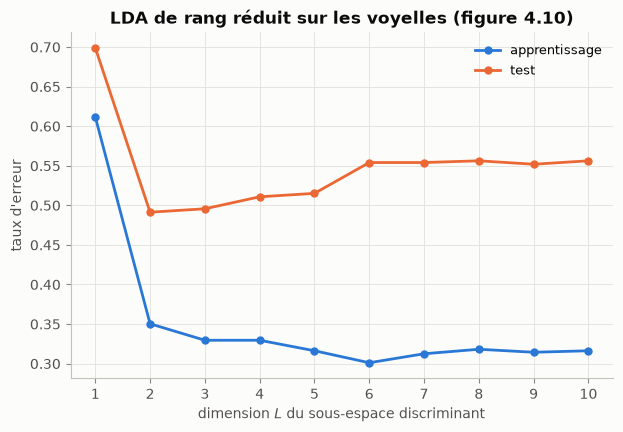

,1,2,3,4,5,6,7,8,9,10
apprentissage,0.612,0.350,0.330,0.330,0.316,0.301,0.312,0.318,0.314,0.316
test,0.699,0.491,0.496,0.511,0.515,0.554,0.554,0.556,0.552,0.556


In [11]:
dims = np.arange(1, p + 1)
err_L = np.array([[c4.error_rate(y, c4.reduced_rank_lda_predict(rr, X, L))
                   for X, y in [(Xtr, ytr), (Xte, yte)]] for L in dims])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dims, err_L[:, 0], "o-", color=BLUE, label="apprentissage")
ax.plot(dims, err_L[:, 1], "o-", color=ORANGE, label="test")
ax.set_title("LDA de rang réduit sur les voyelles (figure 4.10)")
ax.set_xlabel("dimension $L$ du sous-espace discriminant")
ax.set_ylabel("taux d'erreur")
ax.set_xticks(dims)
ax.legend()
plt.show()
pd.DataFrame(err_L.round(3), index=dims, columns=["apprentissage", "test"]).T

L'erreur de test est **minimale en dimension 2** (environ 0,49, contre 0,56 pour la LDA
complète), comme dans le livre : restreindre les centroïdes à un plan agit comme une
régularisation. Pour $L = 10$ on retrouve l'erreur de la LDA du tableau 4.1.

Dans le plan des deux premières variables canoniques, les frontières de décision de la
règle $\hat G_2$ sont des segments de droites (figure 4.11) : ce sont les frontières d'un
diagramme de Voronoï des centroïdes projetés (les classes ayant même effectif).

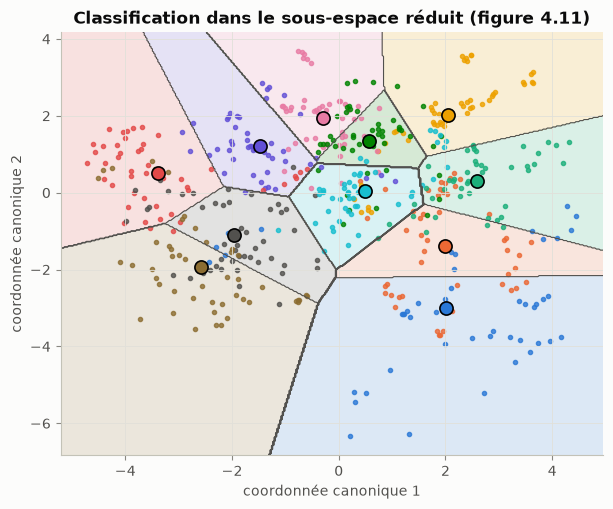

In [12]:
model2 = {"classes": classes, "priors": pi, "means": Zc[:, :2], "cov": np.eye(2)}
pad = 0.5
lim_x = (Ztr[:, 0].min() - pad, Ztr[:, 0].max() + pad)
lim_y = (Ztr[:, 1].min() - pad, Ztr[:, 1].max() + pad)
fig, ax = plt.subplots(figsize=(7, 5.5))
c4.plot_decision_regions(ax, lambda Z: c4.lda_predict(model2, Z), lim_x, lim_y, classes, VOW,
                         n=400, alpha=0.15, linewidth=0.8)
plot_canonical(ax, 0, 1, "Classification dans le sous-espace réduit (figure 4.11)")
plt.show()

> **Remarque.** Dans un sous-espace de dimension $L > 2$, les frontières seraient des
> morceaux d'hyperplans de dimension $L-1$, impossibles à dessiner dans un plan.

## 6. Lien avec la régression sur indicatrices

Le livre signale un lien étroit entre ces directions et la régression de la matrice
indicatrice $\mathbf{Y}$ : les variables canoniques s'obtiennent à partir des
combinaisons linéaires ajustées $\hat{\mathbf{Y}} = \mathbf{X}\hat{\mathbf{B}}$ (le
détail est au chapitre 12). L'exercice 4.3 en donne une conséquence : les colonnes de
$\hat{\mathbf{B}}$ (sans la constante) engendrent **le même sous-espace** que les
directions discriminantes. Vérifions-le numériquement sur les voyelles.

In [13]:
Xc = Xtr - Xtr.mean(axis=0)
Bhat = np.linalg.lstsq(Xc, c4.indicator_matrix(ytr), rcond=None)[0]   # p x K, rang K-1
Q, _ = np.linalg.qr(Bhat[:, :-1])                                     # base de Im(B̂)
residu = V - Q @ (Q.T @ V)
print("Rang de B̂ :", np.linalg.matrix_rank(Bhat))
print("Norme relative de la partie de V hors de Im(B̂) : %.2e" % (np.linalg.norm(residu) / np.linalg.norm(V)))

Rang de B̂ : 10
Norme relative de la partie de V hors de Im(B̂) : 3.87e-16
